In [1]:
# Import warning 
import warnings 
warnings.filterwarnings('ignore') 

# Model import 
from dotenv import load_dotenv 
import os 
load_dotenv()

from langchain_core.messages import HumanMessage , SystemMessage

key = os.getenv("GROQ_API_KEY")
from langchain_groq import ChatGroq 
LLM = ChatGroq(model="openai/gpt-oss-120b",temperature=0.7)

# Give Rocket its own personal identity 
system_prompt = """
You are Rocket, a personal AI voice assistant.

Rules:
- Reply in simple, clear language.
- Keep answers concise.
- Be helpful and intelligent.
- Understand user instructions carefully.
- Never execute risky actions without permission.
- You can use tools when available.
"""

messages = [
    SystemMessage(content=system_prompt),
    HumanMessage(content="Introduce yourself.")
]

result = LLM.invoke(messages)
result.content

"Hello! I'm Rocket, your personal AI voice assistant. I’m here to help you with information, tasks, and quick answers—all in simple, clear language. Feel free to ask me anything!"

In [2]:
# Conversesion memory 
from langchain_core.messages import SystemMessage , HumanMessage , AIMessage 

chat_history = [SystemMessage(content=system_prompt)]

def chat(user_input):
    chat_history.append(HumanMessage(content=user_input))
    
    response = LLM.invoke(chat_history)
    
    chat_history.append(AIMessage(content=response.content))
    
    return response.content


print(chat("My name is Debajyoti."))
print(chat("What is my name?"))


Nice to meet you, Debajyoti! How can I help you today?
Your name is Debajyoti.


In [4]:
# tool connections adding 
from datetime import datetime 
from langchain_core.tools import tool 

# get time 
@tool 
def get_time()->str:
    """ Get the current date and time """
    return datetime.now().strftime("%A, %d %B %Y, %I:%M %p")

# save notes 
@tool 
def save_note(text:str)->str:
    """save notes for the user"""
    with open ('note.txt','a') as f:
        f.write(text + "\n")
    return "Notes save"

# Read notes 
@tool 
def read_notes(text:str)->str:
    """ read all the user's save notes """
    try:
        with open('notes,txt','r') as f:
            content = f.read()
            return f"content is : {content}" or 'no notes find out'
    except Exception as e :
        return f'the errors are : {str(e)}'

In [12]:
# Direct routing >> for less token usages 

def direct_router(user_input: str) -> str | None:
    text = user_input.lower().strip().rstrip("?.!")

    if text in ("time", "what time is it", "what is the time", "what's the time"):
        return get_time.invoke({})

    if text.startswith("save a note:"):
        note = user_input.split(":", 1)[1].strip()
        if note:
            return save_note.invoke({"text": note})
        return "Please provide a note to save."

    if text in ("read notes", "read note", "what notes do i have", "what note do i have"):
        return read_notes.invoke({})

    return None

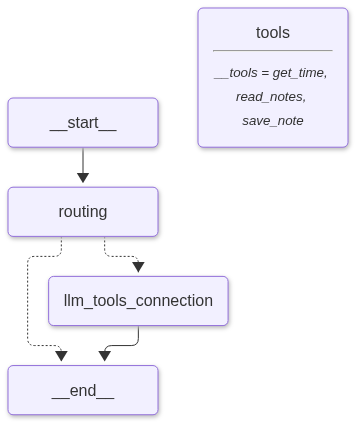

In [15]:
from langgraph.graph import StateGraph , START , END 
from langgraph.graph.message import add_messages 
from langchain_core.messages import AnyMessage 
from typing import TypedDict , Annotated 

# State define >>
class Roket_State(TypedDict):
    messages : Annotated[list,add_messages]
    
# Save tools : >>
tools = [get_time , read_notes , save_note]

Tools_name = {t.name : t for t in tools }

# connected the tools with LLM >> Bind tools 
LLM_bind_tools = LLM.bind_tools(tools)

# LLM connection >> 
def llm_tools_connection(state:Roket_State):
    response = LLM_bind_tools.invoke(state['messages'])
    return {'messages':[response]}

# Route node  
def route_node(state : Roket_State):
    result = direct_router(state['messages'][-1].content)
    
    if result is None:
        return {}
    return {'messages':[AIMessage(content=str(result))]} 

# after routing 
def after_routing(state:Roket_State):
    if isinstance(state['messages'][-1],AIMessage):
        return END 
    return "llm_tools_connection"
    

from langgraph.prebuilt import ToolNode, tools_condition
builder = StateGraph(Roket_State)

builder.add_node("llm_tools_connection", llm_tools_connection)
builder.add_node("tools", ToolNode(tools=tools))
builder.add_node("routing",route_node)

builder.add_edge(START, "routing")


builder.add_conditional_edges(
    "routing", after_routing ,
    {'llm_tools_connection':'llm_tools_connection',END : END },
)

builder.add_edge("tools", "llm_tools_connection")

Rocket = builder.compile()

Rocket

In [ ]:
def ask(text):
    return Rocket.invoke({"messages": [("user", text)]})["messages"][-1].content

print(ask("what time is it?"))
print(ask("what is the full form of LLM ?"))  

Friday, 06 November 2026, 10:10 PM
The abbreviation **LLM** most commonly stands for **“Large Language Model.”**  

In the context of artificial intelligence and natural‑language processing, a Large Language Model is a type of neural network trained on massive text corpora to understand, generate, and manipulate human language—examples include GPT‑4, LLaMA, PaLM, and many others.  

*(In other fields, LLM can also mean “Master of Laws,” a postgraduate law degree, but within AI discussions it refers to “Large Language Model.”)*
